# First Model - Ridge Regression

**Why this model?** We chose Ridge Regression as a regularised linear candidate for our task. The EDA revealed strong relationships between calendar features, a distinct interaction between hour and day type, and a non-linear relationship between temperature and demand. We therefore need to encode these patterns explicitly for a linear model. In addition, several calendar features are structurally dependent, and one-hot encoding introduces correlated predictors. Ridge addresses this by adding an L2 penalty, which helps stabilise coefficient estimates and reduces sensitivity to multicollinearity. Numerical features must also be scaled because the regularisation penalty depends on their magnitude. This model will help us assess how well a regularised linear approach captures demand patterns and how its predictive performance differs between the random, blocked and chronological validation schemes.

## Feature Engineering and Preprocessing

Ridge Regression is a linear model, so feature representation plays an important role in its ability to capture patterns in the data.

We apply different preprocessing steps to different feature groups:

- **Categorical features:** `mnth`, `weekday`, and `weathersit` are one-hot encoded to avoid treating category labels as continuous numerical values.
- **Hour × workingday interaction:** `hr` and `workingday` are combined into a single categorical feature. This allows the model to learn different hourly demand patterns for working days and non-working days.
- **Binary features:** `holiday` and `workingday` are retained as binary indicators.
- **Numerical features:** missing humidity values are imputed using the median, and numerical features are standardised.
- **Temperature:** a quadratic polynomial feature is added to represent a non-linear relationship between temperature and demand.

All preprocessing steps are included in a single scikit-learn pipeline. This ensures that transformations are fitted only on the training data within each validation fold, preventing information leakage from the test data.

In [1]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, PolynomialFeatures, StandardScaler)
import matplotlib.pyplot as plt

from src.data import load_data
from src.validation import RESULTS_DIR, SCHEMES, evaluate, get_cv

In [2]:
X, y = load_data()

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

display(X.head())
display(y.head())

Features shape: (17379, 9)
Target shape: (17379,)


,mnth,hr,holiday,weekday,workingday,weathersit,temp,hum,windspeed
datetime,,,,,,,,,
2011-01-01 00:00:00,1,0,0,6,0,1,0.24,0.81,0.0
2011-01-01 01:00:00,1,1,0,6,0,1,0.22,0.80,0.0
2011-01-01 02:00:00,1,2,0,6,0,1,0.22,0.80,0.0
2011-01-01 03:00:00,1,3,0,6,0,1,0.24,0.75,0.0
2011-01-01 04:00:00,1,4,0,6,0,1,0.24,0.75,0.0


datetime
2011-01-01 00:00:00    16
2011-01-01 01:00:00    40
2011-01-01 02:00:00    32
2011-01-01 03:00:00    13
2011-01-01 04:00:00     1
Name: cnt, dtype: int64

In [3]:
print("Chronological order:", X.index.is_monotonic_increasing)
print("Unique timestamps:", X.index.is_unique)
print("'yr' excluded:", "yr" not in X.columns)
print("Target aligned with features:", X.index.equals(y.index))

print("\nRemaining missing values:")
print(X.isna().sum()[X.isna().sum() > 0])

Chronological order: True
Unique timestamps: True
'yr' excluded: True
Target aligned with features: True

Remaining missing values:
hum    22
dtype: int64


In [4]:
def make_hour_day_category(X):
    X = np.asarray(X)

    hour = X[:, 0].astype(int).astype(str)
    workingday = X[:, 1].astype(int).astype(str)

    return (hour + "_" + workingday).reshape(-1, 1)

In [5]:
# Categorical features
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

# Hour × workingday interaction
hour_day_transformer = Pipeline([
    ("combine", FunctionTransformer(make_hour_day_category, validate=False)),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Numerical features with missing values
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Temperature with a quadratic term
temperature_transformer = Pipeline([
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler())
])

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, ["mnth", "weekday", "weathersit"]),
        ("hour_day", hour_day_transformer, ["hr", "workingday"]),
        ("binary", "passthrough", ["holiday", "workingday"]),
        ("numeric", numeric_transformer, ["hum", "windspeed"]),
        ("temperature", temperature_transformer, ["temp"])
    ],
    remainder="drop"
)

In [7]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

## Ridge Regression and Regularisation

Ridge Regression minimises the squared prediction error with an additional L2 regularisation penalty:

$$\min_{\beta} \left( \sum_{i=1}^{n}(y_i-\hat{y}_i)^2 + \alpha\sum_{j=1}^{p}\beta_j^2 \right)$$

The regularisation parameter `alpha` controls the strength of the penalty:

- A small `alpha` allows coefficients to take larger values, making the model closer to ordinary linear regression.
- A large `alpha` penalises large coefficients more strongly, potentially reducing overfitting but also causing underfitting.

Since the optimal regularisation strength is not known in advance, we use grid search with cross-validation to select `alpha` separately for each training fold.

In [8]:
ALPHAS = np.logspace(-4, 3, 15)
INNER_SPLITS = 3


def make_ridge_search(scheme, log_target=False):
    """Ridge pipeline tuned with an inner CV of the same type as the outer scheme."""
    if log_target:
        estimator = TransformedTargetRegressor(
            regressor=ridge_pipeline, func=np.log1p, inverse_func=np.expm1
        )
        param_grid = {"regressor__model__alpha": ALPHAS}
    else:
        estimator = ridge_pipeline
        param_grid = {"model__alpha": ALPHAS}

    return GridSearchCV(
        estimator,
        param_grid,
        cv=get_cv(scheme, n_splits=INNER_SPLITS),
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )

## Validation Strategy and Hyperparameter Tuning

Both Ridge variants are evaluated under three outer validation schemes defined in `src/validation.py`:

- **Random:** shuffled 5-fold cross-validation. Observations from different time periods can appear in both training and test sets.
- **Blocked:** five contiguous test blocks without shuffling. The training set includes observations from both before and after each test block.
- **Chronological:** expanding-window validation. The first half of the time period is used for initial training, and the remaining observations are divided into five consecutive test blocks. Each test block is predicted using only earlier observations.

The regularisation parameter `alpha` is selected by `GridSearchCV` using three inner splits of the outer training part only. The inner splitter follows the same validation scheme as the outer splitter, ensuring consistency between hyperparameter selection and model evaluation.

After hyperparameter selection, the model is refitted on the entire outer training set and evaluated on the untouched test fold.

The three schemes evaluate different sets of observations, so their fold-averaged scores should not be directly compared. A comparison on common test timestamps across all model families is performed separately in `06_model_comparison.ipynb`.

Chronological validation is the most relevant evaluation setting for assessing the model's ability to predict future demand.

In [9]:
variants = {"ridge": False, "ridge_log": True}

results = {}
for name, log_target in variants.items():
    for scheme in SCHEMES:
        model = make_ridge_search(scheme, log_target)
        results[(name, scheme)] = evaluate(model, X, y, scheme, name)

## Experimental Results

We evaluate two Ridge variants:

- **ridge:** predicts the original target `cnt`.
- **ridge_log:** trains on `log1p(cnt)` and transforms predictions back using `expm1`.

Both variants use the same preprocessing pipeline and hyperparameter search. The only difference is the target transformation.

The models are evaluated using random, blocked, and chronological validation. The table reports the mean and standard deviation of RMSE across the outer folds, together with mean MAE, R², and RMSLE.

These results describe the performance of the two Ridge variants within each validation scheme. Comparisons between different model families and matched-timestamp comparisons are presented separately in `06_model_comparison.ipynb`.

In [10]:
summary_rows = []

for (name, scheme), (folds, _) in results.items():
    summary_rows.append({
        "model": name,
        "scheme": scheme,
        "rmse_mean": folds["rmse"].mean(),
        "rmse_std": folds["rmse"].std(),
        "mae_mean": folds["mae"].mean(),
        "r2_mean": folds["r2"].mean(),
        "rmsle_mean": folds["rmsle"].mean()
    })

ridge_summary = pd.DataFrame(summary_rows)

display(ridge_summary.sort_values(["scheme", "rmse_mean"]).round(3))

,model,scheme,rmse_mean,rmse_std,mae_mean,r2_mean,rmsle_mean
1,ridge,blocked,117.732,21.519,90.936,0.407,1.114
4,ridge_log,blocked,119.316,26.877,82.208,0.447,0.577
2,ridge,chrono,126.881,23.501,96.428,0.588,1.102
5,ridge_log,chrono,128.333,15.136,90.978,0.561,0.568
3,ridge_log,random,81.479,0.925,52.267,0.798,0.434
0,ridge,random,89.099,1.254,65.317,0.758,1.004


**Metrics.** RMSE (Root Mean Squared Error) is the square root of the mean squared prediction error and penalises large errors more strongly. MAE (Mean Absolute Error) measures the average absolute error in rentals per hour. R² measures the proportion of target variance explained by the model relative to predicting the mean. RMSLE (Root Mean Squared Logarithmic Error) measures errors on the logarithmic scale and places more emphasis on relative differences.

For RMSLE, negative predictions are clipped to zero before applying the logarithm. This means RMSLE does not reflect how far below zero the original predictions were, so negative prediction rates are reported separately.

In [11]:
def summarise(name, scheme):
    folds = pd.read_csv(RESULTS_DIR / f"{name}_{scheme}_folds.csv")

    return {
        "model": name,
        "scheme": scheme,
        "rmse_mean": folds["rmse"].mean(),
        "rmse_std": folds["rmse"].std(),
        "mae_mean": folds["mae"].mean(),
        "r2_mean": folds["r2"].mean(),
        "rmsle_mean": folds["rmsle"].mean(),
    }

ridge_names = ["ridge", "ridge_log"]

ridge_summary = pd.DataFrame([summarise(name, scheme) for name in ridge_names for scheme in SCHEMES])

display(ridge_summary.round(3))

,model,scheme,rmse_mean,rmse_std,mae_mean,r2_mean,rmsle_mean
0,ridge,random,89.099,1.254,65.317,0.758,1.004
1,ridge,blocked,117.732,21.519,90.936,0.407,1.114
2,ridge,chrono,126.881,23.501,96.428,0.588,1.102
3,ridge_log,random,81.479,0.925,52.267,0.798,0.434
4,ridge_log,blocked,119.316,26.877,82.208,0.447,0.577
5,ridge_log,chrono,128.333,15.136,90.978,0.561,0.568


In [12]:
rows = []
for (name, scheme), (folds, _) in results.items():
    alpha = folds["best_params"].str.extract(r"alpha'?: (?:np\.float64\()?([0-9.eE+-]+)")[0].astype(float)
    rows.append(pd.DataFrame({"model": name, "scheme": scheme, "fold": folds["fold"], "alpha": alpha}))

alphas = pd.concat(rows)
alphas.pivot_table(index=["model", "scheme"], columns="fold", values="alpha").map("{:.1e}".format)

fold                     1        2        3        4        5
model     scheme                                              
ridge     blocked  1.0e+01  3.2e+01  3.2e+01  3.2e+01  3.2e+01
          chrono   1.0e-04  3.2e-04  1.0e-04  1.0e-02  1.0e-03
          random   3.2e-01  3.2e-01  3.2e-01  3.2e-01  3.2e-01
ridge_log blocked  1.0e+00  1.0e+01  1.0e+01  3.2e+01  3.2e+01
          chrono   1.0e+00  1.0e-04  1.0e-04  1.0e-04  1.0e-04
          random   1.0e-04  1.0e-04  3.2e-04  1.0e-04  1.0e-04

## Fold-Level Performance Analysis

The average cross-validation score provides an overall estimate of model performance, but it does not show whether the model performs consistently across different test periods.

This is particularly important for chronological validation, where each fold represents a different period in time.

We therefore examine the individual fold scores and their corresponding test periods. This helps identify whether prediction errors are concentrated in specific periods and whether performance changes as the training window expands.

In [13]:
for name in ["ridge", "ridge_log"]:
    folds = results[(name, "chrono")][0]
    print(f"\n{name}")
    display(folds.drop(columns="best_params").round({"rmse": 1, "mae": 1, "r2": 3, "rmsle": 3}))


ridge


,fold,n_train,n_test,test_start,test_end,rmse,mae,r2,rmsle
0,1,8657,1746,2012-01-01 12:00:00,2012-03-14 13:00:00,94.4,80.3,0.522,1.735
1,2,10403,1753,2012-03-14 14:00:00,2012-05-26 16:00:00,139.5,102.0,0.565,0.850
2,3,12156,1754,2012-05-26 17:00:00,2012-08-07 18:00:00,137.8,100.4,0.604,0.781
3,4,13910,1754,2012-08-07 19:00:00,2012-10-19 20:00:00,151.8,110.0,0.598,0.689
4,5,15664,1715,2012-10-19 21:00:00,2012-12-31 23:00:00,110.8,89.5,0.653,1.453



ridge_log


,fold,n_train,n_test,test_start,test_end,rmse,mae,r2,rmsle
0,1,8657,1746,2012-01-01 12:00:00,2012-03-14 13:00:00,111.4,78.2,0.335,0.734
1,2,10403,1753,2012-03-14 14:00:00,2012-05-26 16:00:00,138.1,98.3,0.574,0.560
2,3,12156,1754,2012-05-26 17:00:00,2012-08-07 18:00:00,126.2,89.2,0.668,0.454
3,4,13910,1754,2012-08-07 19:00:00,2012-10-19 20:00:00,148.6,107.3,0.615,0.491
4,5,15664,1715,2012-10-19 21:00:00,2012-12-31 23:00:00,117.4,81.9,0.611,0.601


In [14]:
for (name, scheme), (_, preds) in results.items():
    print(f"{name:10s} {scheme:8s} negative predictions: {(preds['y_pred'] < 0).mean():.2%}")

ridge      random   negative predictions: 9.94%
ridge      blocked  negative predictions: 9.07%
ridge      chrono   negative predictions: 12.19%
ridge_log  random   negative predictions: 0.00%
ridge_log  blocked  negative predictions: 0.00%
ridge_log  chrono   negative predictions: 0.00%


## Prediction Analysis: Actual vs Predicted

We compare predicted values with the actual bike rental counts to examine how well the model captures the target distribution.

A perfect model would place all observations on the diagonal line where predicted values equal actual values.

Deviations from this line may reveal systematic errors, such as underestimating high-demand periods or overestimating low-demand periods.

We focus on chronological predictions because they better represent the task of forecasting future observations.

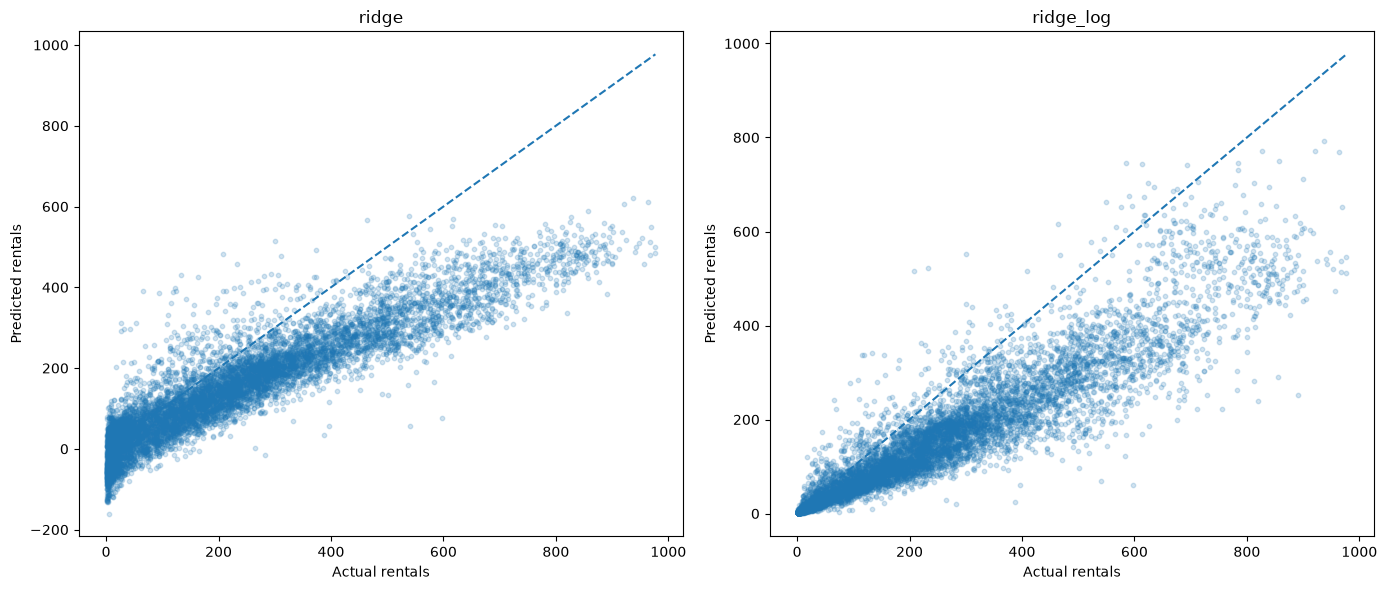

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name in zip(axes, ["ridge", "ridge_log"]):
    preds = results[(name, "chrono")][1]

    ax.scatter(preds["y_true"], preds["y_pred"], alpha=0.2, s=10)

    max_value = max(preds["y_true"].max(), preds["y_pred"].max())
    ax.plot([0, max_value], [0, max_value], linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Actual rentals")
    ax.set_ylabel("Predicted rentals")

plt.tight_layout()
plt.savefig("figures/ridge/Actual_vs_Predicted_Rentals.png", dpi=150, bbox_inches="tight")
plt.show()

**Actual vs predicted.** Both variants underestimate high demand: above approximately 400 rentals, most observations lie below the diagonal. Plain Ridge produces negative predictions for some low-demand observations, reaching approximately -150. The log-transformed variant produces no negative predictions in the current evaluation results, although the log transformation does not mathematically guarantee non-negative predictions.

The residual plots show increasing dispersion as predicted demand grows. This indicates non-constant error variance, while the predominance of positive residuals at higher predicted values confirms that both variants struggle to capture high demand.

## Residual Analysis

Residuals are calculated as the difference between actual and predicted values:

$$
e_i = y_i - \hat{y}_i
$$

Residual analysis helps identify systematic patterns that may not be visible in aggregate evaluation metrics.

Ideally, residuals should be distributed around zero without clear systematic patterns. We examine residuals against predicted demand to check for systematic bias and changes in error magnitude across the target range.

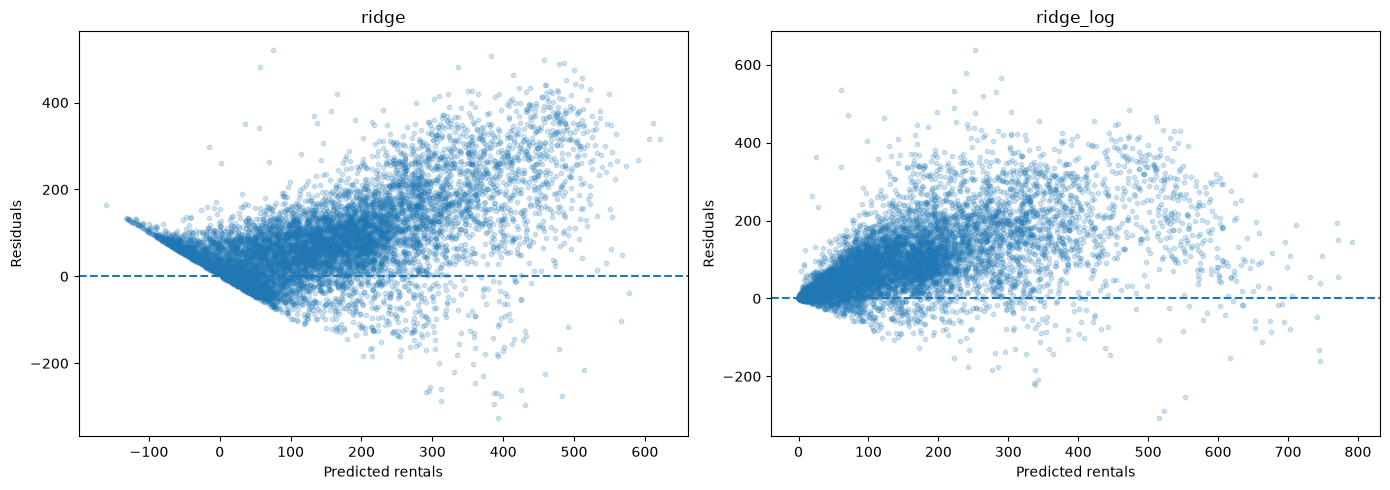

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name in zip(axes, ["ridge", "ridge_log"]):
    preds = results[(name, "chrono")][1]
    residuals = preds["y_true"] - preds["y_pred"]

    ax.scatter(
        preds["y_pred"],
        residuals,
        alpha=0.2,
        s=10
    )
    ax.axhline(0, linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Predicted rentals")
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.savefig("figures/ridge/ridge_residuals_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

## Error Analysis

Aggregate metrics hide where the model fails. For the chronological predictions (2012) we look at the absolute error by hour and day type, at the bias (mean residual) over time, and at the largest individual errors.

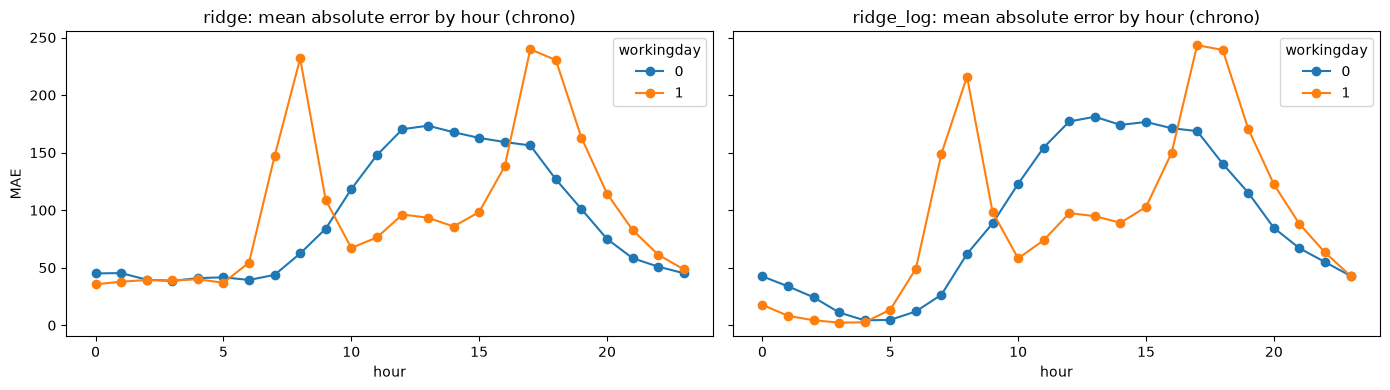

In [17]:
def error_table(name, scheme="chrono"):
    table = results[(name, scheme)][1].join(X)
    table["resid"] = table["y_true"] - table["y_pred"]
    table["abs_err"] = table["resid"].abs()
    return table


fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, name in zip(axes, ["ridge", "ridge_log"]):
    err = error_table(name).groupby(["workingday", "hr"])["abs_err"].mean().unstack("workingday")
    err.plot(ax=ax, marker="o")
    ax.set_title(f"{name}: mean absolute error by hour (chrono)")
    ax.set_xlabel("hour")
    ax.set_ylabel("MAE")
    ax.legend(title="workingday")
plt.tight_layout()
plt.savefig("figures/ridge/ridge_mae_by_hour_and_workingday_chrono.png", dpi=150, bbox_inches="tight")
plt.show()

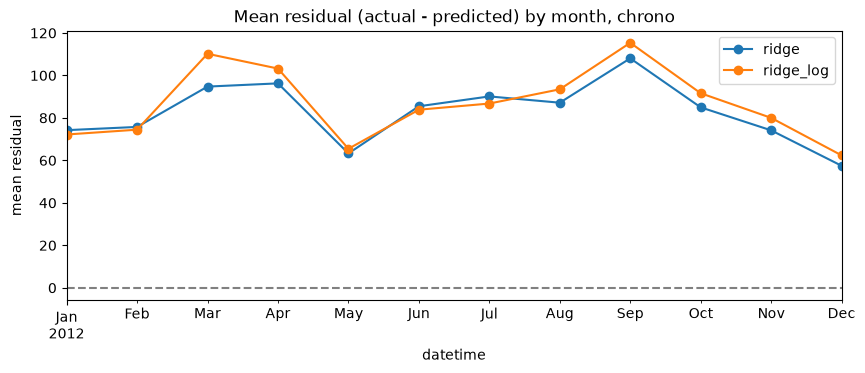

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for name in ["ridge", "ridge_log"]:
    error_table(name)["resid"].resample("MS").mean().plot(ax=ax, marker="o", label=name)
ax.axhline(0, linestyle="--", color="grey")
ax.set_title("Mean residual (actual - predicted) by month, chrono")
ax.set_ylabel("mean residual")
ax.legend()
plt.savefig("ridge_mean_residual_by_month_chrono.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
for name in ["ridge", "ridge_log"]:
    r = error_table(name)["resid"]
    print(f"{name:10s} mean residual: {r.mean():.1f}   share of MSE due to bias: {r.mean()**2 / (r**2).mean():.1%}")

ridge      mean residual: 82.6   share of MSE due to bias: 41.2%
ridge_log  mean residual: 86.6   share of MSE due to bias: 44.9%


In [20]:
cols = ["y_true", "y_pred", "resid", "hr", "workingday", "weathersit", "temp", "hum", "windspeed"]
error_table("ridge_log").nlargest(10, "abs_err")[cols].round(2)

,y_true,y_pred,resid,hr,workingday,weathersit,temp,hum,windspeed
datetime,,,,,,,,,
2012-08-01 18:00:00,891,252.72,638.28,18,1,3,0.76,0.62,0.22
2012-07-10 18:00:00,819,239.35,579.65,18,1,3,0.70,0.74,0.22
2012-10-01 17:00:00,856,290.07,565.93,17,1,3,0.56,0.60,0.25
2012-04-16 08:00:00,597,61.31,535.69,8,0,2,0.56,0.83,0.16
2012-07-16 17:00:00,755,222.75,532.25,17,1,3,0.76,0.66,0.58
2012-08-14 17:00:00,812,281.81,530.19,17,1,3,0.76,0.66,0.25
2012-06-06 18:00:00,782,263.37,518.63,18,1,3,0.60,0.53,0.19
2012-04-16 17:00:00,712,222.54,489.46,17,0,1,0.80,0.33,0.39
2012-03-23 17:00:00,957,472.51,484.49,17,1,2,0.72,0.42,0.16


In [21]:
tbl = error_table("ridge_log")
tbl["peak"] = tbl["hr"].isin([7, 8, 9, 17, 18, 19]) & (tbl["workingday"] == 1)
tbl.groupby(["peak", "weathersit"])["resid"].agg(["count", "mean"]).round(1)

count   mean
peak  weathersit              
False 1            4803   72.9
      2            1909   62.4
      3             519   47.3
True  1             953  186.9
      2             417  160.7
      3             121  131.7

**Error analysis: findings.** The absolute error is largest at the commuting peaks of working days (about 08:00 and 17:00-18:00) and around midday on non-working days, i.e. where demand is highest; plain Ridge also errs by about 40 rentals at night because of negative predictions, which the log variant avoids. The mean residual is positive in every month of 2012 (roughly +57 to +115 rentals per hour), so both models systematically underestimate the demand of 2012; this reflects the growth between the years, which models without year information or lagged demand cannot represent. Seven of the ten largest errors are working-day peak hours with `weathersit = 3` and demand of 800-900 that is predicted at 220-300, which suggests that the additive weather effect is too strong at peak hours; two others are on 16 April 2012, a non-working day with a commuting-like profile (probably a local holiday, to be verified).

## Conclusions

### 1. Performance of the Ridge Variants

The experiment evaluated two Ridge Regression variants: one trained on the original target and another trained on its logarithmic transformation.

Under chronological validation, the standard Ridge model achieves a mean RMSE of 126.9 and a mean MAE of 96.4 rentals per hour. The log-transformed variant achieves a similar RMSE of 128.3 but a lower MAE of 91.0.

This indicates that the log transformation improves typical absolute prediction error, while the standard Ridge model performs slightly better in terms of RMSE. The log variant also achieves a lower mean RMSLE (0.568 compared with 1.102).

Therefore, the target transformation changes the error profile, but neither variant is consistently better across all metrics.

### 2. Effect of Target Transformation

The standard Ridge model produces negative predictions in 12.19% of chronological test observations. The log-transformed variant produces no negative predictions in the evaluated test observations.

The transformation also reduces chronological MAE by approximately 5.5 rentals per hour. However, it does not reduce RMSE, which remains slightly higher than that of the standard Ridge model.

Thus, the log transformation improves the typical absolute error and the logarithmic-scale metric in this experiment, but it does not eliminate large prediction errors or systematic underestimation.

### 3. Regularisation and Hyperparameter Selection

The selected regularisation parameter `alpha` varies across validation schemes and outer folds.

Blocked validation generally favours stronger regularisation, while several chronological folds and random folds for the log-transformed variant select values close to the lower boundary of the tested grid.

This suggests that the preferred regularisation strength depends on the training data and its temporal distribution. The selection of the lower boundary (`1e-4`) in several folds also indicates that testing smaller values could be useful in a further sensitivity analysis.

The current results do not establish a globally optimal value of `alpha`.

### 4. Error Analysis

Both Ridge variants systematically underestimate bike-sharing demand during the chronological test period. Their mean residuals are approximately +82.6 and +86.6 rentals per hour, respectively.

The squared mean residual accounts for 41.2% of the MSE for standard Ridge and 44.9% for the log-transformed variant. This indicates that systematic bias is a substantial component of the prediction error.

The largest errors occur mainly during working-day commuting peaks, especially in the evening. The models also show larger residual dispersion at higher predicted demand levels, suggesting that the error variance is not constant.

The log transformation removes negative predictions in the evaluated observations, but it does not resolve the tendency to underestimate high-demand periods.

### 5. Limitations

Ridge Regression is linear in its engineered feature space. Although the model includes a quadratic temperature term and an hour-by-workingday interaction, it cannot automatically capture arbitrary non-linear relationships or higher-order interactions.

The model also excludes year information and lagged demand. Consequently, it cannot directly represent the substantial increase in rental demand between 2011 and 2012 or use recent rental history to predict future demand.

The dataset covers only two years in one city, which limits the generalisability of the findings. Finally, the selected regularisation strength varies between folds, and some searches select the lower boundary of the tested grid.

Overall, Ridge Regression provides an interpretable linear approach that captures several important demand patterns, but it struggles with high-demand periods and systematic changes in demand over time.

A comparison with the baseline models, Random Forest, and Gradient Boosting, including the selection of the overall best model, is presented separately in `06_model_comparison.ipynb`.